# Prototype Comparison Based on Key Metrics

**Objective**  
Compare Flow A (no button) and Flow B (with button) across key evaluation metrics and formulate recommendations on which variant to advance to the production A/B test.

**Agenda**
1. Setup and Data Ingestion
2. Target Feature Extraction
3. Primary Metric: Future Discount Noticeability  
   3.1. Comparison Between Flows  
   3.2. Sensitivity Analysis: Age and Gender  
4. Diagnostic Analysis  
   4.1. Current Discount Noticeability  
   4.2. Joint Discount Noticeability  

###  1. Setup and Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from scipy import stats
import pingouin as pg
import statsmodels.stats.proportion as smprop
import statsmodels.formula.api as smf

In [2]:
# display settings for high-dimensional dataset
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 50)

In [3]:
# Load the dataset. Low_memory = False handles mixed types across columns
DATA_PATH = '../data/P1_FTD_cleaned_sample.csv'
df = pd.read_csv(DATA_PATH, low_memory = False)
print(f"Cleaned dataset loaded: {df.shape[0]} sessions, {df.shape[1]} columns")

Cleaned dataset loaded: 198 sessions, 175 columns


### 2. Target Feature Extraction

Further analysis focuses on the following target dimensions and survey variables:

**Primary Metric: Discount Noticeability**
- **Future Discount Noticeability (Retention Hook):**  
  Multi-select prompt: `'Q18. Did you notice any of the following additional details during the deposit process? Select all that apply. A discount was promised for future payments'`

**Diagnostic Metric: Current Discount Noticeability**
- **Applied Discount Noticeability (Current):**  
  Multi-select prompt: `'Q14. Did you notice any of the following during the deposit process? Select all that apply. A discount was applied'`

**Deep Dive: Comprehension of Repeat-Use Rules**
- **Payment Method Attribution.** Did users link the discount specifically to the payment method?  
  Single-select: `'Q22. How do you think the future discount will be given? Answer'`  
  *Target answer:* `'The discount will be given only if the same payment method is used'`
- **Time Constraint Awareness.** Did users recognize the 7-day redemption window?  
  Single-select: `'Q20. To which payments will this future discount be applied? Answer'`  
  *Target answer:* `'It will apply only if a payment is made within a specific period'`  
  Open-ended numeric: `'Q21. Within how many days should the next payment be made for the discount to apply? (Please enter the number of the days) Answer'`  
  *Target answer:* `7` (answers `<= 7 days` are accepted as valid retention window awareness, since a shorter perceived deadline maintains urgency, whereas values `> 7 days` miss the offer condition).
- **Discount Magnitude Recall.** Did users recall the exact incentive size (1%)?  
  Open-ended numeric: `'Q19. You noticed that a discount was promised for future payments. What was the amount of the discount promised? (Please specify the amount in %) Answer'`  
  *Target answer:* `1` or `1%`

**Diagnostic Evaluation: Offer Appeal**
- **Declared Intent to Switch Payment Method:**  
  Single-select: `'Q28. So, a 1% discount was applied to your current deposit, and a 1% discount was also promised on future deposits if they are made within 7 days using the same payment method. If you noticed this, would you make your next deposit using this payment method instead of your usual one? Answer'`  
  *Target answers:* `'Definitely yes, I would switch to this payment method'` / `'Probably yes, I would consider using this payment method'`
- **Declared Willingness to Deposit Within 7 Days:**  
  Single-select: `'Q30. Would you make a special effort to make your next deposit within 7 days to receive this 1% discount? Answer'`  
  *Target answer:* `'Yes'`
- **Historical Responsiveness to Time-Limited Offers (benchmark):**  
  Single-select: `'Q32. Think back to the last time an online investment, crypto, or trading platform offered you a limited-time bonus or discount if you acted within a certain time. Did you do it in time to get the bonus/discount? Answer'`  
  *Target answer:* `'Yes, I did it in time to get the bonus/discount'`

In [4]:
#function to extract col names using prefix ans substring 
def col_extractor (prefix: str = '', substring: str = ''):
    match = [c for c in df.columns if c.lower().startswith (prefix.lower()) and substring.lower() in c.lower()]
    if len (match) > 1:
        raise ValueError (f'Multiple matches for {prefix} and {substring}: {match}')
    elif not match:
        raise KeyError (f'Nothing found for {prefix} and {substring}')
    return match[0]


#map short feature name  -> (prefix, substring)
FEATURE_SCHEMA = {
    #Primary Metric: Discount Noticeability*
    "current_discount_noticed": ("Q14.", "A discount was applied"),
    "future_discount_noticed": ("Q18.", "A discount was promised for future payments"),

    #Deep Dive: Comprehension of Repeat-Use Rules
    "method_attribution": ("Q22.", ""),
    "time_constraint_aware": ("Q20.", ""),
    "time_constraint_days": ("Q21.", ""),
    "discount_magnitude_recalled": ("Q19.", "(Please specify the amount in %) Answer"),

    #Diagnostic Evaluation: Offer Appeal
    "intent_to_switch": ("Q28.", ""),
    "willingness_to_deposit_7d": ("Q30.", ""),
    "historical_promo_usage": ("Q32.", ""),

    #technical cols
    "flow": ("flow", ""),
    "age": ("age", ""),
    "gender": ("Q3.", "gender"),
}

#building dict long feature name ->  short feature name
long_short_names_mapped = {col_extractor(prefix, substring): short_name for short_name, (prefix, substring) in FEATURE_SCHEMA.items()}

#print final mapping to double-check 
for key, value in long_short_names_mapped.items():
    print (key,"\n/", value, '/\n')

Q14. Did you notice any of the following during the deposit process?
Select all that apply. A discount was applied 
/ current_discount_noticed /

Q18. Did you notice any of the following additional details during the deposit process?
Select all that apply. A discount was promised for future payments 
/ future_discount_noticed /

Q22. How do you think the future discount will be given? Answer 
/ method_attribution /

Q20. To which payments will this future discount be applied? Answer 
/ time_constraint_aware /

Q21. Within how many days should the next payment be made for the discount to apply? (Please enter the number of the days) Answer 
/ time_constraint_days /

Q19. You noticed that a discount was promised for future payments. 
What was the amount of the discount promised? (Please specify the amount in %) Answer 
/ discount_magnitude_recalled /

Q28. So, a 1% discount was applied to your current deposit, and a 1% discount was also promised on future deposits if they are made within 

In [5]:
#create a dataset with selected cols only
df_extracted = df[list(long_short_names_mapped)].rename(columns = long_short_names_mapped)

print(f'rows {df_extracted.shape[0]}, columns {df_extracted.shape[1]}')
df_extracted.head(3)


rows 198, columns 12


,current_discount_noticed,future_discount_noticed,method_attribution,time_constraint_aware,time_constraint_days,discount_magnitude_recalled,intent_to_switch,willingness_to_deposit_7d,historical_promo_usage,flow,age,gender
0,A discount was applied,NaN,NaN,NaN,NaN,NaN,"Probably yes, I would consider using this paym...",No,"No, I didn’t do it in time",Flow A (no button),34,Male
1,A discount was applied,A discount was promised for future payments,The discount will be given by the website wher...,It will apply only if a payment is made within...,7 days,1%,"Probably yes, I would consider using this paym...",No,I’ve never been offered this kind of bonus/dis...,Flow A (no button),33,Female
2,A discount was applied,NaN,NaN,NaN,NaN,NaN,"Definitely yes, I would switch to this payment...",It’s hard to say,"Yes, I did it in time to get the bonus/discount",Flow A (no button),21,Male


### 3. Primary Metric: Future Discount Noticeability

**Objective**  
Compare how often respondents in Flow A and Flow B noticed the future discount when prompted. Users need to notice the offer before it can encourage repeat use. 

**Analysis Plan**  
   3.1. Main analysis: Future discount noticeability   
   3.2. Additional analysis: Sensitivity analysis   

#### 3.1. Future discount noticeability (`future_discount_noticed`)

**Objective:** Establish which flow is more effective at driving future-discount noticeability  

**Steps:**
- Compare respondent counts and percentages by flow, report the absolute difference
- Test whether the observed difference is statistically significant (two-sided two-proportion z-test at alpha = 0.05)
- Report group proportions and the estimated difference with 95% confidence intervals (Wilson and Newcombe methods)

In [6]:
#convert target cols to boolean indicators
df_extracted['future_discount_noticed'] = df_extracted['future_discount_noticed'].notna()
df_extracted['current_discount_noticed'] = df_extracted['current_discount_noticed'].notna()

In [7]:
#calculate counts and percentages for the key metric - future-discount noticeability 
future_dsc_noticed_counts = pd.crosstab(df_extracted['future_discount_noticed'], df_extracted['flow'] )

future_dsc_noticed_pct = future_dsc_noticed_counts.div(future_dsc_noticed_counts.sum(axis=0), axis = 'columns').mul(100)
future_dsc_noticed_pct['delta_pp'] = future_dsc_noticed_pct['Flow A (no button)'] - future_dsc_noticed_pct['Flow B (with button)']

print('Counts')
display(future_dsc_noticed_counts)

print('Percentages')
display(future_dsc_noticed_pct.round(2))

Counts


flow,Flow A (no button),Flow B (with button)
future_discount_noticed,,
False,57,75
True,43,23


Percentages


flow,Flow A (no button),Flow B (with button),delta_pp
future_discount_noticed,,,
False,57.0,76.53,-19.53
True,43.0,23.47,19.53


Future-discount noticeability is higher in Flow A than in Flow B (43.00% vs. 23.47%), an observed difference of 19.53 percentage points.

I use a two-sided **two-proportion z-test** at a significance level of alpha = 0.05 to assess whether noticeability rates differ between the flows.

- H0: The noticeability rates are equal (p_A = p_B).
- H1: The noticeability rates differ (p_A ≠ p_B).

The test assumptions are satisfied:
- The outcome is binary
- The samples are independent: each respondent tested only one flow. 

Additionally below I inspect if expected counts of both outcomes under the null hypothesis exceed 10 in each group, supporting the normal approximation

In [8]:
# сheck expected counts against the rule-of-thumb threshold of 10
#extract counts and sample sizes for the flows
future_dsc_flow_a_b = ['Flow A (no button)', 'Flow B (with button)']
future_dsc_noticed_counts_ztest = future_dsc_noticed_counts.loc[True, future_dsc_flow_a_b]
future_dsc_noticed_samples_ztest = future_dsc_noticed_counts.loc[:, future_dsc_flow_a_b].sum(axis=0)

#calculate pooled proportions
future_dsc_pooled_noticeability = (
    future_dsc_noticed_counts_ztest.sum() / future_dsc_noticed_samples_ztest.sum()
)

#calculate expected counts
future_dsc_exp_counts_for_ztest = pd.DataFrame({
    'noticed': future_dsc_noticed_samples_ztest * future_dsc_pooled_noticeability,
    'not_noticed': future_dsc_noticed_samples_ztest * (1.0 - future_dsc_pooled_noticeability)
})

display(future_dsc_exp_counts_for_ztest.round(2))

,noticed,not_noticed
flow,,
Flow A (no button),33.33,66.67
Flow B (with button),32.67,65.33


In [9]:
#run z-test for proportions
ALPHA = 0.05
future_dsc_z_stat, future_dsc_p_val = smprop.proportions_ztest(
    count = future_dsc_noticed_counts_ztest, 
    nobs = future_dsc_noticed_samples_ztest, 
    alternative='two-sided')

#print results
future_dsc_delta_pp = float(future_dsc_noticed_pct.loc[True, 'delta_pp'])
print (f'The observed difference between flows: {future_dsc_delta_pp:.2f} p.p.')
print (f'Z stat: {future_dsc_z_stat:.4f}')
print (f'P value: {future_dsc_p_val:.4f}')

if future_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if future_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed future-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed future-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')


The observed difference between flows: 19.53 p.p.
Z stat: 2.9148
P value: 0.0036
Reject H0 at 0.05: the noticeability rates differ significantly.
Flow A demonstrates a higher observed future-discount noticeability compared to Flow B


Next, I calculate 95% confidence intervals for each flow's noticeability rate using the Wilson method and for the difference between flows
(A − B) using the Newcombe method (it combines the two Wilson intervals).

These methods are chosen for their generally more reliable coverage compared with standard Wald intervals.

In [10]:
# Calculate 95% Wilson confidence intervals for each flow's noticeability rate
future_dsc_noticed_ci_low, future_dsc_noticed_ci_high = (smprop.proportion_confint(
                                                         count = future_dsc_noticed_counts_ztest,
                                                         nobs  = future_dsc_noticed_samples_ztest,
                                                         alpha = ALPHA, 
                                                         method='wilson')
                                                         )

# extract noticeability percentages for display
future_dsc_noticeability_pct = future_dsc_noticed_pct.loc[True, future_dsc_flow_a_b] #percantages to display

# Build the results table
future_dsc_noticed_ci_results = pd.DataFrame({
    'sample_size': future_dsc_noticed_samples_ztest,
    'noticed_count': future_dsc_noticed_counts_ztest,
    'noticeability_rate_pct': future_dsc_noticeability_pct,
    'ci_low_pct': future_dsc_noticed_ci_low*100,
    'ci_high_pct': future_dsc_noticed_ci_high*100
})

display(future_dsc_noticed_ci_results.round(2))

,sample_size,noticed_count,noticeability_rate_pct,ci_low_pct,ci_high_pct
flow,,,,,
Flow A (no button),100,43,43.00,33.73,52.78
Flow B (with button),98,23,23.47,16.18,32.76


In [11]:
# Calculate 95% Newcombe confidence intervals for the difference between flows (A − B)
future_dsc_delta_ci_low, future_dsc_delta_ci_high = (smprop.confint_proportions_2indep(
                                                         count1 = future_dsc_noticed_counts_ztest.loc['Flow A (no button)'],
                                                         count2 = future_dsc_noticed_counts_ztest.loc['Flow B (with button)'],
                                                         nobs1  = future_dsc_noticed_samples_ztest.loc['Flow A (no button)'],
                                                         nobs2  = future_dsc_noticed_samples_ztest.loc['Flow B (with button)'],
                                                         alpha = ALPHA, 
                                                         compare ='diff',
                                                         method='newcomb')
                                                         )


# print the results

print (f'Confidence intervals for the difference between flows (A vs B) are {future_dsc_delta_ci_low*100:.2f} p.p.-{future_dsc_delta_ci_high*100:.2f} p.p.')


Confidence intervals for the difference between flows (A vs B) are 6.41 p.p.-31.73 p.p.


In [12]:
#prepare results 
future_dsc_delta_pp = float(future_dsc_noticed_pct.loc[True, 'delta_pp'])

future_dsc_noticed_rate_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'noticeability_rate_pct']
future_dsc_noticed_ci_low_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'ci_low_pct']
future_dsc_noticed_ci_high_pct_flow_a = future_dsc_noticed_ci_results.loc['Flow A (no button)', 'ci_high_pct']

future_dsc_noticed_rate_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'noticeability_rate_pct']
future_dsc_noticed_ci_low_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'ci_low_pct']
future_dsc_noticed_ci_high_pct_flow_b = future_dsc_noticed_ci_results.loc['Flow B (with button)', 'ci_high_pct']


# print noticeability rates and confidence intervals
print (f"""Future-discount noticeability
Flow A (no button) - {future_dsc_noticed_rate_pct_flow_a:.2f}% (95% Wilson CI: {future_dsc_noticed_ci_low_pct_flow_a:.2f}% to {future_dsc_noticed_ci_high_pct_flow_a:.2f}%)
Flow B (with button) - {future_dsc_noticed_rate_pct_flow_b:.2f}% (95% Wilson CI: {future_dsc_noticed_ci_low_pct_flow_b:.2f}% to {future_dsc_noticed_ci_high_pct_flow_b:.2f}%)
""")

# print the estimated difference and its confidence interval
print (f'The observed difference between flows (A - B): {future_dsc_delta_pp:.2f} p.p. (95% Newcombe CI: {future_dsc_delta_ci_low*100:.2f} p.p. to {future_dsc_delta_ci_high*100:.2f} p.p.)')

# print the hypothesis test result
print ('Two-sided two-proportion z-test')
print (f'Z stat = {future_dsc_z_stat:.4f}; P value  = {future_dsc_p_val:.4f}')

if future_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if future_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed future-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed future-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')

Future-discount noticeability
Flow A (no button) - 43.00% (95% Wilson CI: 33.73% to 52.78%)
Flow B (with button) - 23.47% (95% Wilson CI: 16.18% to 32.76%)

The observed difference between flows (A - B): 19.53 p.p. (95% Newcombe CI: 6.41 p.p. to 31.73 p.p.)
Two-sided two-proportion z-test
Z stat = 2.9148; P value  = 0.0036
Reject H0 at 0.05: the noticeability rates differ significantly.
Flow A demonstrates a higher observed future-discount noticeability compared to Flow B


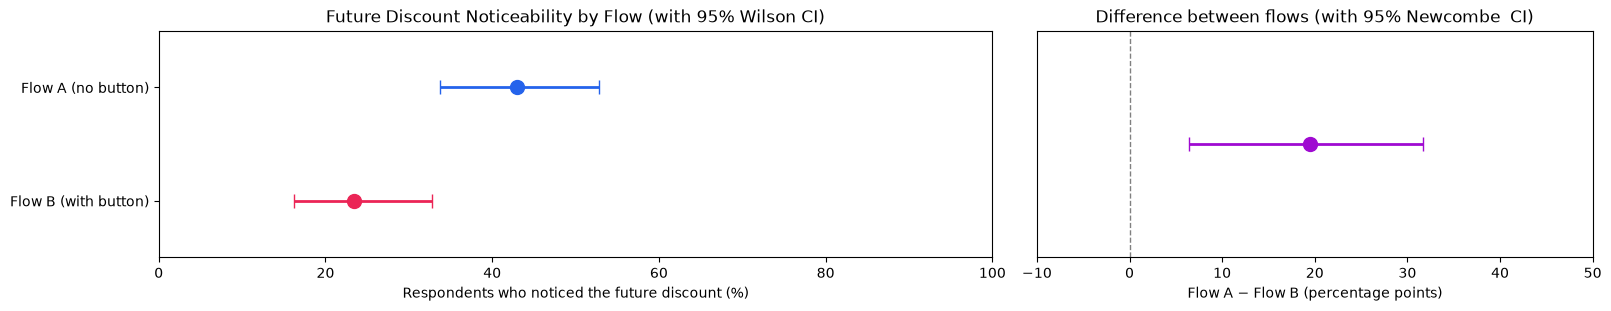

In [13]:
#мisualise the noticeability rates, the difference and their CIs
future_dsc_fig, future_dsc_axes = plt.subplots(ncols = 2, 
                                               figsize = (16,3),
                                               gridspec_kw = {'width_ratios': [1.5, 1]},
                                               layout = 'constrained')

#plot Flow A rate with its CI
future_dsc_axes[0].errorbar( x = future_dsc_noticed_rate_pct_flow_a,
                            y = 1, 
                            xerr = [[future_dsc_noticed_rate_pct_flow_a - future_dsc_noticed_ci_low_pct_flow_a],
                                    [future_dsc_noticed_ci_high_pct_flow_a - future_dsc_noticed_rate_pct_flow_a]],
                            fmt = 'o',
                            color = '#2563EB',
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#plot Flow B rate with its CI
future_dsc_axes[0].errorbar( x = future_dsc_noticed_rate_pct_flow_b,
                            y = 2, 
                            xerr = [[future_dsc_noticed_rate_pct_flow_b - future_dsc_noticed_ci_low_pct_flow_b],
                                    [future_dsc_noticed_ci_high_pct_flow_b - future_dsc_noticed_rate_pct_flow_b]],
                            fmt = 'o',
                            color = "#EB2556",
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#rate plots settings
future_dsc_axes[0].set (
    title = 'Future Discount Noticeability by Flow (with 95% Wilson CI)',
    xlabel='Respondents who noticed the future discount (%)',
    yticks=[1, 2],
    yticklabels=future_dsc_flow_a_b,
    xlim = (0, 100),
    ylim = (2.5, 0.5)
)

future_dsc_axes[1].errorbar( x = future_dsc_delta_pp,
                            y = 1, 
                            xerr = [[future_dsc_delta_pp - future_dsc_delta_ci_low*100],
                                    [future_dsc_delta_ci_high*100 - future_dsc_delta_pp]],
                            fmt = 'o',
                            color = "#9F0AD1",
                            markersize=10,
                            capsize=5,
                            elinewidth=2
                            )

#difference plots settings
future_dsc_axes[1].set (
    title = 'Difference between flows (with 95% Newcombe  CI)',
    xlabel='Flow A − Flow B (percentage points)',
    yticks=[],
    xlim = (-10, 50),
    ylim = (0.5, 1.5)
)

# Mark no difference between flows
future_dsc_axes[1].axvline(
    x=0,
    color='gray',
    linestyle='--',
    linewidth=1
)

plt.show()

**Interim Conclusion**

**Flow A (no button) demonstrates higher prompted future-discount noticeability than Flow B (with the “Accept and close” button): 43.00% vs 23.47%, a difference of +19.53 percentage points (95% Newcombe CI: +6.41 to +31.73 pp). The difference is statistically significant (two-sided two-proportion z-test, z = 2.91, p = 0.0036).**  
The confidence interval excludes zero but remains wide, indicating uncertainty about the size of Flow A's advantage.
*Note: This result does not establish an effect on actual repeat-payment behavior.*

The observed direction is opposite to the initial hypothesis that clicking "Accept and close" would encourage more deliberate processing
of the offer and improve recall. 
One possible explanation* is habitual pop-up dismissal ("cookie-banner blindness"): users may click "Accept and close" without reading the offer. In Flow B, this action also removes the reminder from the final payment confirmation screen, reducing opportunities to notice it.  
*This behavioral explanation remains a hypothesis. The comparison does not isolate habitual dismissal from the effect of fewer reminder exposures.* 

#### 3.2. Sensitivity analysis

**Objective:** Test whether Flow A's advantage holds after accounting for age and gender differences.

**Rationale**: Notebook 02 showed the largest observed differences in gender and age composition. Flow A has a higher share of men (+9.71 pp) and adults aged 55–65 (+7.84 pp), while Flow B has a higher share of adults aged 18–34 (+8.04 pp). We therefore check whether accounting for age and gender changes the comparison of future-discount noticeability.

**Steps:**
- Apply stratificated approach to review results by gender and age buckets for preliminary analysis
- Fit an unadjusted (flow only) and adjusted logistic regression model (flow, age, gender) to compare 
- Calculate odds ratios, 95% confidence intervals, and p-values for both models
- Compare effect sizes to confirm whether Flow A's advantage remains stable

In [14]:
df_extracted.head(2)

,current_discount_noticed,future_discount_noticed,method_attribution,time_constraint_aware,time_constraint_days,discount_magnitude_recalled,intent_to_switch,willingness_to_deposit_7d,historical_promo_usage,flow,age,gender
0,True,False,NaN,NaN,NaN,NaN,"Probably yes, I would consider using this paym...",No,"No, I didn’t do it in time",Flow A (no button),34,Male
1,True,True,The discount will be given by the website wher...,It will apply only if a payment is made within...,7 days,1%,"Probably yes, I would consider using this paym...",No,I’ve never been offered this kind of bonus/dis...,Flow A (no button),33,Female


In [15]:
#сalculate future-discount noticeability by flow and gender
future_dsc_noticeability_gender_pct = pd.crosstab(
    index=df_extracted["future_discount_noticed"],
    columns=[
        df_extracted["flow"],
        df_extracted["gender"],
    ],
    normalize="columns",
).mul(100).round(0)

display(future_dsc_noticeability_gender_pct)

flow                    Flow A (no button)       Flow B (with button)      
gender                              Female  Male               Female  Male
future_discount_noticed                                                    
False                                 50.0  59.0                 71.0  79.0
True                                  50.0  41.0                 29.0  21.0

In [16]:
#create age groups
age_bins = [17, 34, 54, 65]
age_labels = ['18-34', '35-54', '55-65']
df_extracted['age_group'] = pd.cut (df_extracted['age'], bins = age_bins, right = True, labels = age_labels)

#сalculate future-discount noticeability by flow and age group
future_dsc_noticeability_age_group_pct = pd.crosstab(
    index=df_extracted["future_discount_noticed"],
    columns=[
        df_extracted["flow"],
        df_extracted["age_group"],
    ],
    normalize="columns",
).mul(100).round(0)

display(future_dsc_noticeability_age_group_pct)

flow                    Flow A (no button)             Flow B (with button)  \
age_group                            18-34 35-54 55-65                18-34   
future_discount_noticed                                                       
False                                 64.0  48.0  62.0                 80.0   
True                                  36.0  52.0  38.0                 20.0   

flow                                 
age_group               35-54 55-65  
future_discount_noticed              
False                    74.0  62.0  
True                     26.0  38.0

Overall conclusion
The subgroup comparisons suggest that differences in age and gender composition are unlikely to fully explain Flow A’s higher overall noticeability. Flow A had higher noticeability among both women and men, and in two of the three age groups.

Women also reported noticing the future discount more often than men in both flows. Since Flow B included a higher share of women, this difference in gender composition could improve its overall noticeability rate, making Flow A’s advantage appear smaller.

Next step
The tables compare the flows separately by gender and age group. Next, I use logistic regression to account for age and gender together and check whether this changes the estimated difference between flows.

In [17]:
#prepare a dataset to run logistic regressions
future_dsc_model_data = df_extracted[["future_discount_noticed", "flow", "age", "gender"]]
future_dsc_model_data["future_discount_noticed"] = future_dsc_model_data["future_discount_noticed"].astype(int)

In [18]:

#spesify the unadjusted model and clearly set Flow B as the reference group to reflect previous A-B comparison
future_dsc_unadjusted_model = smf.logit(
    formula=( "future_discount_noticed ~ C(flow, Treatment(reference='Flow B (with button)'))" ),
    data=future_dsc_model_data
)

#estimate the parameters of the model
future_dsc_unadjusted_results = future_dsc_unadjusted_model.fit()

display(future_dsc_unadjusted_results.summary())

Optimization terminated successfully.
         Current function value: 0.614800
         Iterations 5


<class 'statsmodels.iolib.summary.Summary'>
"""
                              Logit Regression Results                             
===================================================================================
Dep. Variable:     future_discount_noticed   No. Observations:                  198
Model:                               Logit   Df Residuals:                      196
Method:                                MLE   Df Model:                            1
Date:                     Fri, 30 Oct 2026   Pseudo R-squ.:                 0.03411
Time:                             22:44:15   Log-Likelihood:                -121.73
converged:                            True   LL-Null:                       -126.03
Covariance Type:                 nonrobust   LLR p-value:                  0.003364
==============================================================================================================================================
                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                     -1.1820      0.238     -4.959      0.000      -1.649      -0.715
C(flow, Treatment(reference='Flow B (with button)'))[T.Flow A (no button)]     0.9001      0.312      2.881      0.004       0.288       1.512
==============================================================================================================================================
"""

In [19]:
# сonvert the unadjusted model coefficient and confidence limits
# from the log-odds scale to the odds ratio scale

#save the name of the coefficient comparing Flow A with Flow B
FUTURE_DSC_FLOW_TERM = ("C(flow, Treatment(reference='Flow B (with button)'))[T.Flow A (no button)]")

#extract the difference in log-odds between Flow A and Flow B
future_dsc_unadj_log_odds_coef = future_dsc_unadjusted_results.params.loc[FUTURE_DSC_FLOW_TERM]
#exponentiate the coef to get the odds ratio for Flow A vs. Flow B
future_dsc_unadj_odds_ratio = np.exp(future_dsc_unadj_log_odds_coef)

#Extract the 95% CI to get the interval for the odds ratio
future_dsc_unadj_log_odds_ci = (future_dsc_unadjusted_results.conf_int(alpha=0.05).loc[FUTURE_DSC_FLOW_TERM])
#exponentiate CI borders from log-odds to the odds ratio scale
future_dsc_unadj_odds_ratio_ci = np.exp(future_dsc_unadj_log_odds_ci)

#extract the p-value for the Flow A vs. Flow B coefficient
future_dsc_unadj_p_value = (future_dsc_unadjusted_results.pvalues.loc[FUTURE_DSC_FLOW_TERM])

#build a one-row results table.
future_dsc_unadj_or_results = pd.DataFrame({
    "model": ["Unadjusted"],
    "comparison": ["Flow A vs. Flow B"],
    "odds_ratio": [future_dsc_unadj_odds_ratio],
    "ci_low": [future_dsc_unadj_odds_ratio_ci.loc[0]],
    "ci_high": [future_dsc_unadj_odds_ratio_ci.loc[1]],
    "p_value": [future_dsc_unadj_p_value],
})

# Round only the displayed values, keeping full precision in the table.
display(future_dsc_unadj_or_results.round(3))

,model,comparison,odds_ratio,ci_low,ci_high,p_value
0,Unadjusted,Flow A vs. Flow B,2.46,1.333,4.538,0.004


The unadjusted odds of noticing the future discount are 2.46 times as high in Flow A as in Flow B (95% CI: 1.33–4.54; p = 0.004).

Next, I fit a model that also accounts for age and gender and compare the results with the unadjusted model.

In [20]:
#spesify the adjusted model and clearly set Flow B as the reference group to reflect previous A-B comparison
#add age as a numeric predictor and gender with Female as the reference.
future_dsc_adjusted_model = smf.logit(
    formula=( "future_discount_noticed ~ "
    "C(flow,Treatment(reference='Flow B (with button)')) "
    "+ age "
    "+ C(gender, Treatment(reference='Female'))" 
    ),
    data=future_dsc_model_data
)

#estimate the parameters of the model
future_dsc_adjusted_results = future_dsc_adjusted_model.fit()

display(future_dsc_adjusted_results.summary())

Optimization terminated successfully.
         Current function value: 0.606650
         Iterations 5


<class 'statsmodels.iolib.summary.Summary'>
"""
                              Logit Regression Results                             
===================================================================================
Dep. Variable:     future_discount_noticed   No. Observations:                  198
Model:                               Logit   Df Residuals:                      194
Method:                                MLE   Df Model:                            3
Date:                     Fri, 30 Oct 2026   Pseudo R-squ.:                 0.04692
Time:                             22:44:15   Log-Likelihood:                -120.12
converged:                            True   LL-Null:                       -126.03
Covariance Type:                 nonrobust   LLR p-value:                  0.008003
==============================================================================================================================================
                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                     -1.5914      0.591     -2.692      0.007      -2.750      -0.433
C(flow, Treatment(reference='Flow B (with button)'))[T.Flow A (no button)]     0.9181      0.319      2.879      0.004       0.293       1.543
C(gender, Treatment(reference='Female'))[T.Male]                              -0.4179      0.335     -1.247      0.213      -1.075       0.239
age                                                                            0.0179      0.014      1.326      0.185      -0.009       0.044
==============================================================================================================================================
"""

In [21]:
# сonvert the adjusted model coefficient and confidence limits
# from the log-odds scale to the odds ratio scale

#extract the difference in log-odds between Flow A and Flow B
future_dsc_adj_log_odds_coef = future_dsc_adjusted_results.params.loc[FUTURE_DSC_FLOW_TERM]
#exponentiate the coef to get the odds ratio for Flow A vs. Flow B
future_dsc_adj_odds_ratio = np.exp(future_dsc_adj_log_odds_coef)

#Extract the 95% CI to get the interval for the odds ratio
future_dsc_adj_log_odds_ci = (future_dsc_adjusted_results.conf_int(alpha=0.05).loc[FUTURE_DSC_FLOW_TERM])
#exponentiate CI borders from log-odds to the odds ratio scale
future_dsc_adj_odds_ratio_ci = np.exp(future_dsc_adj_log_odds_ci)

#extract the p-value for the Flow A vs. Flow B coefficient
future_dsc_adj_p_value = (future_dsc_adjusted_results.pvalues.loc[FUTURE_DSC_FLOW_TERM])

#build a one-row results table.
future_dsc_adj_or_results = pd.DataFrame({
    "model": ["Adjusted"],
    "comparison": ["Flow A vs. Flow B"],
    "odds_ratio": [future_dsc_adj_odds_ratio],
    "ci_low": [future_dsc_adj_odds_ratio_ci.loc[0]],
    "ci_high": [future_dsc_adj_odds_ratio_ci.loc[1]],
    "p_value": [future_dsc_adj_p_value],
})

# Round only the displayed values, keeping full precision in the table.
display(future_dsc_adj_or_results.round(3))

,model,comparison,odds_ratio,ci_low,ci_high,p_value
0,Adjusted,Flow A vs. Flow B,2.505,1.341,4.679,0.004


After accounting for age and gender, the odds of noticing the future discount are 2.51 times as high in Flow A as in Flow B (95% CI: 1.34–4.68; p = 0.004).

The adjusted estimate is close to the unadjusted estimate (OR = 2.46). Accounting for age and gender does not materially change the observed advantage of Flow A in this model.

**Future Discount Noticeability: Conclusion**

Flow A is the stronger option for making the future discount noticeable:

- In this prototype study, 43.00% of respondents in Flow A reported noticing the offer, compared with 23.47% in Flow B. This advantage of 19.53 pp is statistically significant (p = 0.0036).
- The 95% confidence interval for this difference ranges from 6.41 to 31.73 pp. This supports a positive advantage for Flow A, although its exact size remains uncertain.

The samples differed somewhat in age and gender composition. However, the sensitivity analysis showed that the result remained similar after accounting for both characteristics, adding confidence that Flow A’s advantage is not simply due to differences in sample composition.

**These findings support taking Flow A forward as the preferred option for communicating the future discount. Whether this higher noticeability leads to more repeat payments still needs to be tested in production.**

### 4. Diagnostic Analysis: Discount Noticeability

**Objective**  
Compare how often respondents in Flow A and Flow B noticed the current discount when prompted, and examine whether they noticed both the current and future discounts.

**Analysis Plan**  
4.1. Current discount noticeability  
4.2. Joint discount noticeability

#### 4.1. Current Discount Noticeability (`current_discount_noticed`)

**Objective:** Compare how often respondents in Flow A and Flow B noticed the discount applied to their current payment when prompted (Q14).

**Steps:**
- Compare respondent counts and percentages by flow, report the absolute difference
- Test whether the observed difference is statistically significant (two-sided two-proportion z-test at alpha = 0.05)
- Report the estimated difference with 95% confidence intervals (Newcombe methods)


In [22]:
#calculate counts and percentages for current discount noticeability 
current_dsc_noticed_counts = pd.crosstab (df_extracted['current_discount_noticed'], df_extracted['flow'])

current_dsc_noticed_pct = current_dsc_noticed_counts.div(current_dsc_noticed_counts.sum(axis = 0), axis = "columns").mul(100)
current_dsc_noticed_pct['delta_pp'] = current_dsc_noticed_pct['Flow A (no button)'] - current_dsc_noticed_pct['Flow B (with button)']

print('Counts')
display(current_dsc_noticed_counts)

print('Percentages')
display(current_dsc_noticed_pct.round(2))

Counts


flow,Flow A (no button),Flow B (with button)
current_discount_noticed,,
False,45,53
True,55,45


Percentages


flow,Flow A (no button),Flow B (with button),delta_pp
current_discount_noticed,,,
False,45.0,54.08,-9.08
True,55.0,45.92,9.08


Current discount noticeability is higher in Flow A than in Flow B (55.00% vs. 45.92%), an observed difference of 9.08 percentage points.

I use a two-sided **two-proportion z-test** at a significance level of alpha = 0.05 to assess whether noticeability rates differ between the flows.

- H0: The noticeability rates are equal (p_A = p_B).
- H1: The noticeability rates differ (p_A ≠ p_B).

The test assumptions are satisfied:
- The outcome is binary
- The samples are independent: each respondent tested only one flow

Additionally below I inspect if expected counts of both outcomes under the null hypothesis exceed 10 in each group, supporting the normal approximation

In [23]:
# сheck expected counts against the rule-of-thumb threshold of 10
#extract counts and sample sizes for the flows
current_dsc_flow_a_b = ['Flow A (no button)', 'Flow B (with button)']
current_dsc_noticed_counts_ztest = current_dsc_noticed_counts.loc[True, current_dsc_flow_a_b]
current_dsc_noticed_samples_ztest = current_dsc_noticed_counts.loc[:, current_dsc_flow_a_b].sum(axis=0)

#calculate pooled proportions
current_dsc_pooled_noticeability = (
    current_dsc_noticed_counts_ztest.sum() / current_dsc_noticed_samples_ztest.sum()
)

#calculate expected counts
current_dsc_exp_counts_for_ztest = pd.DataFrame({
    'noticed': current_dsc_noticed_samples_ztest * current_dsc_pooled_noticeability,
    'not_noticed': current_dsc_noticed_samples_ztest * (1.0 - current_dsc_pooled_noticeability)
})

display(current_dsc_exp_counts_for_ztest.round(2))

,noticed,not_noticed
flow,,
Flow A (no button),50.51,49.49
Flow B (with button),49.49,48.51


In [24]:
#run z-test for proportions
ALPHA = 0.05
current_dsc_z_stat, current_dsc_p_val = smprop.proportions_ztest(
    count = current_dsc_noticed_counts_ztest, 
    nobs = current_dsc_noticed_samples_ztest, 
    alternative='two-sided')

#print results
current_dsc_delta_pp = float(current_dsc_noticed_pct.loc[True, 'delta_pp'])
print (f'The observed difference between flows: {current_dsc_delta_pp:.2f} p.p.')
print (f'Z stat: {current_dsc_z_stat:.4f}')
print (f'P value: {current_dsc_p_val:.4f}')

if current_dsc_p_val<=ALPHA:
    print (f"Reject H0 at {ALPHA}: the noticeability rates differ significantly.")
    if current_dsc_delta_pp > 0:
        print ('Flow A demonstrates a higher observed current-discount noticeability compared to Flow B')
    else:
        print ('Flow B demonstrates a higher observed current-discount noticeability compared to Flow A')
else:
    print ('Do not reject H0: there is insufficient evidence of a difference in noticeability rates.')


The observed difference between flows: 9.08 p.p.
Z stat: 1.2779
P value: 0.2013
Do not reject H0: there is insufficient evidence of a difference in noticeability rates.


In [25]:
# Calculate 95% Newcombe confidence intervals for the difference between flows (A − B)
current_dsc_delta_ci_low, current_dsc_delta_ci_high = (smprop.confint_proportions_2indep(
                                                         count1 = current_dsc_noticed_counts_ztest.loc['Flow A (no button)'],
                                                         count2 = current_dsc_noticed_counts_ztest.loc['Flow B (with button)'],
                                                         nobs1  = current_dsc_noticed_samples_ztest.loc['Flow A (no button)'],
                                                         nobs2  = current_dsc_noticed_samples_ztest.loc['Flow B (with button)'],
                                                         alpha = ALPHA, 
                                                         compare ='diff',
                                                         method='newcomb')
                                                         )


# print the results

print (f'Confidence intervals for the difference between flows (A vs B) are {current_dsc_delta_ci_low*100:.2f} p.p.-{current_dsc_delta_ci_high*100:.2f} p.p.')


Confidence intervals for the difference between flows (A vs B) are -4.77 p.p.-22.45 p.p.


Current-discount noticeability was higher in Flow A than in Flow B (55.00% vs. 45.92%), an observed difference of +9.08 percentage points. However, the difference was not statistically significant (two-sided two-proportion z-test, p = 0.2013).

The 95% Newcombe confidence interval for the difference (A − B) ranges from −4.77 to +22.45 percentage points. The interval includes zero and remains wide, so the data do not establish a difference in current-discount noticeability or equivalence between the flows.

In both flows, respondents reported noticing the current discount more often than the future discount. One possible explanation is that an immediate benefit is easier to notice, so its noticeability may depend less on repeated reminders or the dismissal button.

#### 4.2. Joint Discount Noticeability

**Objective:** Compare which parts of the offer respondents noticed: both discounts, only one, or neither.

**Steps:**
- Group respondents into four categories: both discounts noticed, current discount only, future discount only, and neither discount noticed.
- Compare counts and percentages within each flow.
- Explain what these patterns suggest about how users noticed the offer.

In [26]:
#intersect 'current_discount_noticed' and 'future_discount_noticed' to build a column 'joint_discount_noticeability'
df_extracted['joint_discount_noticeability'] = (np.select (condlist = [
    df_extracted['current_discount_noticed'] & df_extracted['future_discount_noticed'],
    df_extracted['current_discount_noticed'] & ~df_extracted['future_discount_noticed'],
    ~df_extracted['current_discount_noticed'] & df_extracted['future_discount_noticed']
    ],
choicelist = [
    'Both discounts noticed',
    'Current discount only',
    'Future discount only'
    ],
default = 'Neither discount noticed'
))

In [27]:
#calculate counts and percentages for joint discount noticeability 
joint_dsc_noticeability_counts = pd.crosstab (df_extracted['joint_discount_noticeability'], df_extracted['flow'])

joint_dsc_noticeability_pct = joint_dsc_noticeability_counts.div(joint_dsc_noticeability_counts.sum(axis = 0), axis = "columns").mul(100)
joint_dsc_noticeability_pct['delta_pp'] = joint_dsc_noticeability_pct['Flow A (no button)'] - joint_dsc_noticeability_pct['Flow B (with button)']

print('Counts')
display(joint_dsc_noticeability_counts)

print('Percentages')
display(joint_dsc_noticeability_pct.round(2))

Counts


flow,Flow A (no button),Flow B (with button)
joint_discount_noticeability,,
Both discounts noticed,25,15
Current discount only,30,30
Future discount only,18,8
Neither discount noticed,27,45


Percentages


flow,Flow A (no button),Flow B (with button),delta_pp
joint_discount_noticeability,,,
Both discounts noticed,25.0,15.31,9.69
Current discount only,30.0,30.61,-0.61
Future discount only,18.0,8.16,9.84
Neither discount noticed,27.0,45.92,-18.92


The observed shares in the four categories differ between flows.  
I use a Pearson chi-square test at alpha = 0.05 to assess whether the distribution of these four categories differs between flows.

- H0: The distribution of joint discount noticeability is the same across flows.
- H1: The distribution of joint discount noticeability differs across flows.

In [28]:
joint_dsc_chi2_expected, _, joint_dsc_chi2_stats = pg.chi2_independence (data = df_extracted, x = 'joint_discount_noticeability', y = 'flow')
print ('Expected counts under H0')
display (joint_dsc_chi2_expected.round(2))

print ('Chi2 test results')
display (joint_dsc_chi2_stats.loc[joint_dsc_chi2_stats['test'].eq('pearson')].round(4))


Expected counts under H0


flow,Flow A (no button),Flow B (with button)
joint_discount_noticeability,,
Both discounts noticed,20.20,19.80
Current discount only,30.30,29.70
Future discount only,13.13,12.87
Neither discount noticed,36.36,35.64


Chi2 test results


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,10.8271,3.0,0.0127,0.2338,0.797


The distribution of joint discount noticeability differs significantly between flows (Pearson χ² = 10.83, df = 3, p = 0.0127)*.

**Flow A shows higher overall discount noticeability.**  
The largest absolute difference is in the "Neither discount noticed" category: 27.00% in Flow A vs. 45.92% in Flow B, a difference of −18.92 percentage points.
More respondents in Flow A noticed only the future discount (18.00% vs. 8.16%, +9.84 pp) or both discounts (25.00% vs. 15.31%, +9.69 pp).
The share who noticed only the current discount was nearly the same: 30.00% in Flow A vs. 30.61% in Flow B, a difference of −0.61 pp.
This pattern is consistent with the primary finding that Flow A makes the future discount more noticeable. 

**However, even in Flow A, 57% of respondents did not report noticing the future discount: 27% noticed neither discount, and 30% noticed only the current discount.** This leaves room to improve how the future offer is communicated. It also points to a potential budget risk: the current discount may be given without users noticing the incentive to return.

Noticing the future offer does not mean users understood its conditions or will act on it. The next analysis examines whether they understood the payment method and time limit.

_*The test assesses the distribution as a whole; it does not establish which individual category differences are statistically significant._

